In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

df = pd.read_csv(
    "../data/cleaned_employee_data.csv"
)

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [2]:
#target variable 
df['Attrition'].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

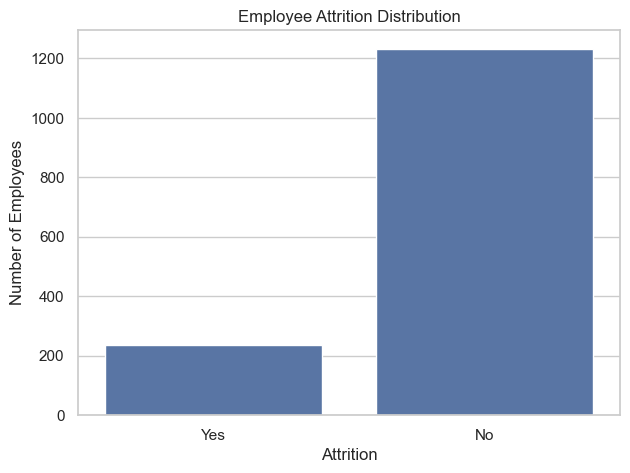

In [3]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Attrition'
)

plt.title('Employee Attrition Distribution')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')

plt.show()

In [4]:
#Attrition rate 

total_employees = len(df)

employees_left = (df['Attrition'] == 'Yes').sum()

attrition_rate = (
    employees_left / total_employees
) * 100

print(f"Total Employees: {total_employees}")
print(f"Employees Left: {employees_left}")
print(f"Attrition Rate: {attrition_rate:.2f}%")

Total Employees: 1470
Employees Left: 237
Attrition Rate: 16.12%


In [5]:
numerical_cols = df.select_dtypes(
    include=['int64', 'float64']
).columns

print(numerical_cols.tolist())

['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [6]:
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


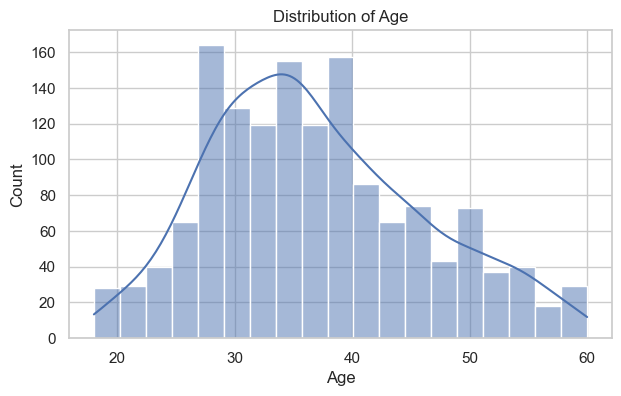

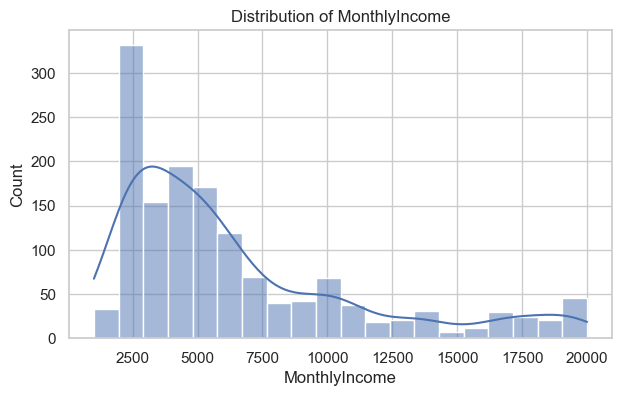

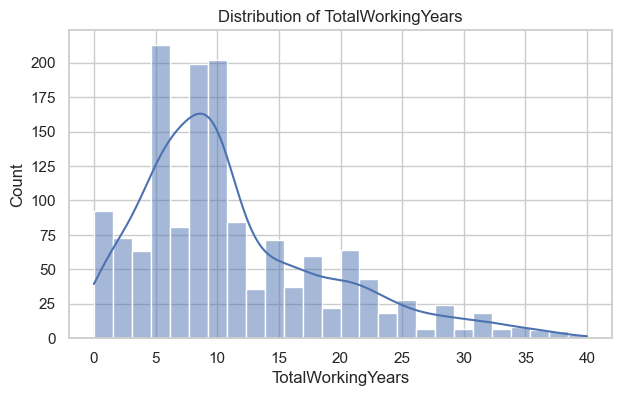

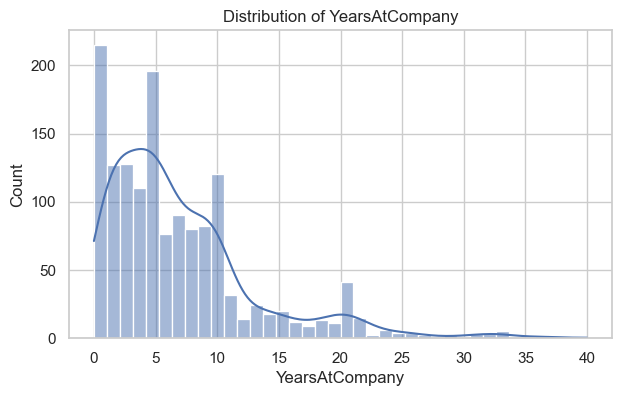

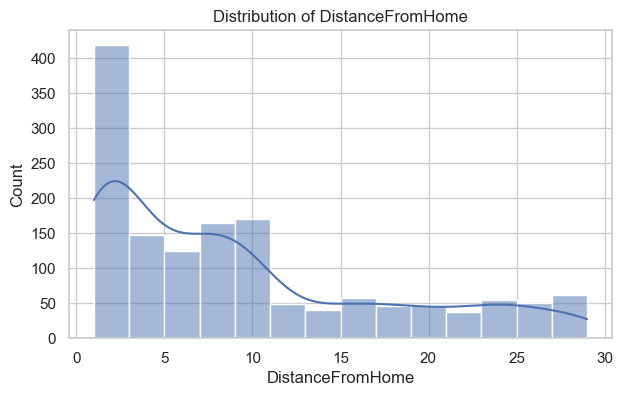

In [7]:
features = [
    'Age',
    'MonthlyIncome',
    'TotalWorkingYears',
    'YearsAtCompany',
    'DistanceFromHome'
]

for col in features:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True
    )

    plt.title(f'Distribution of {col}')
    plt.show()

In [8]:
categorical_cols = df.select_dtypes(
    include='object'
).columns

print(categorical_cols.tolist())

['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


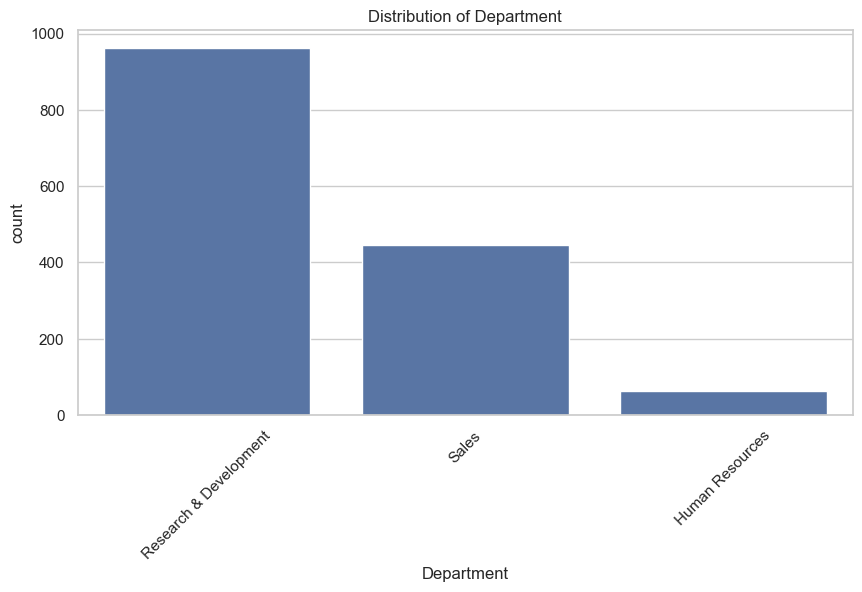

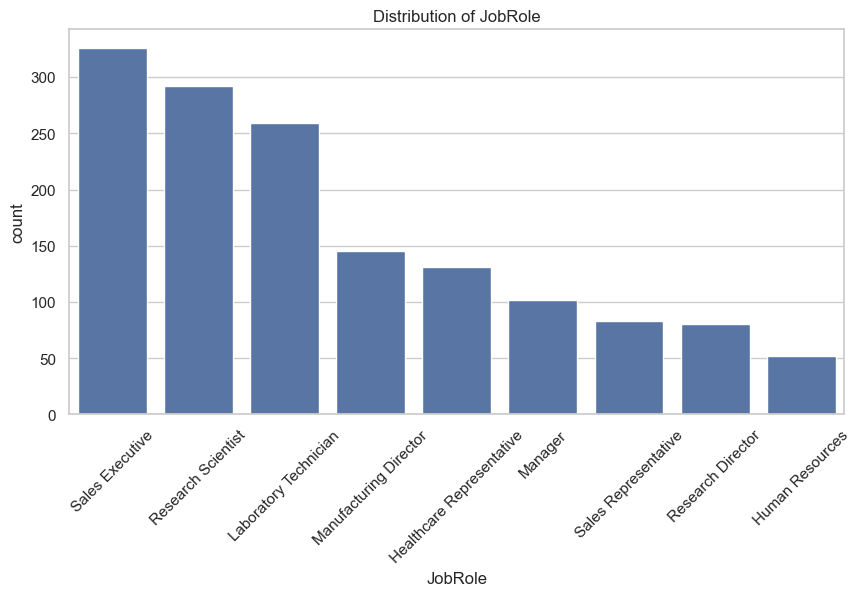

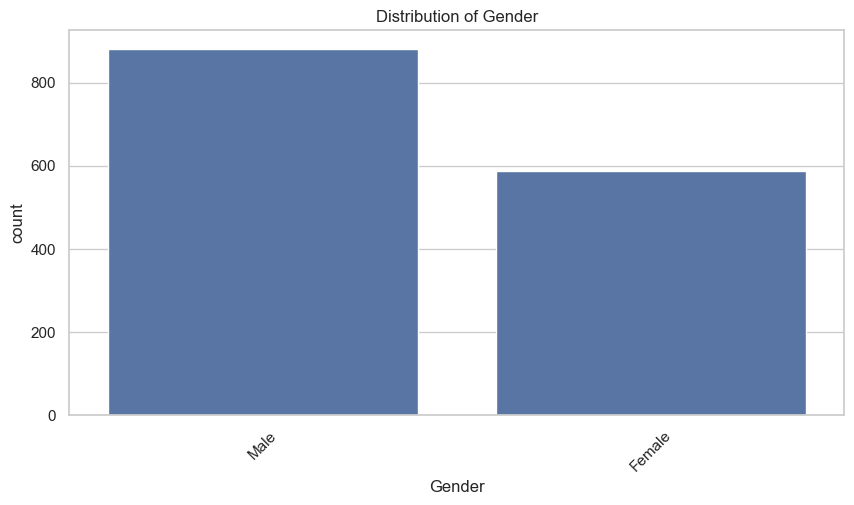

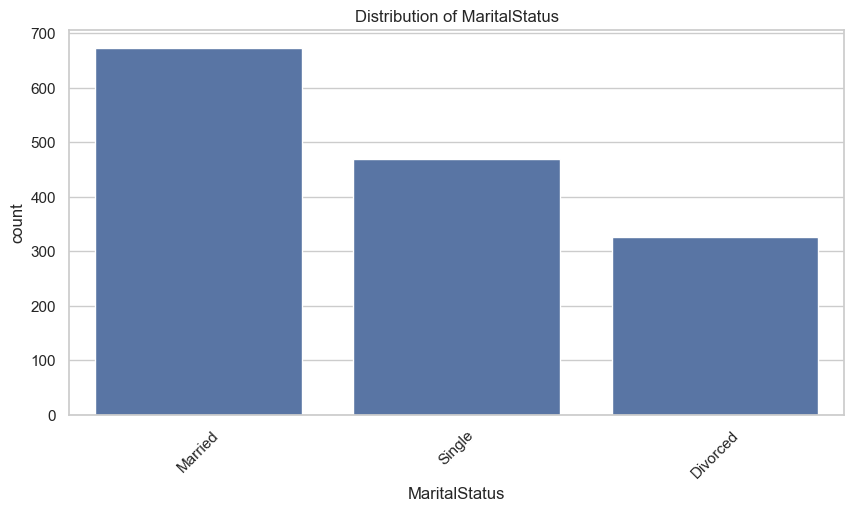

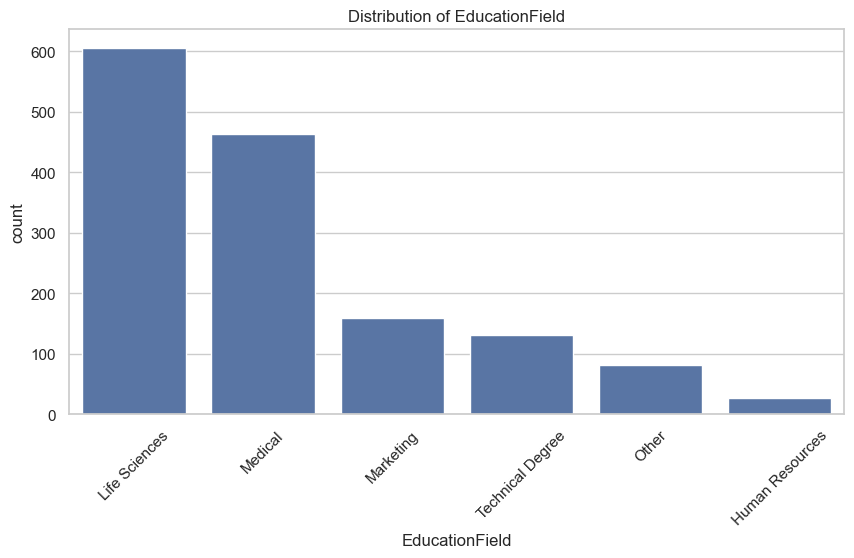

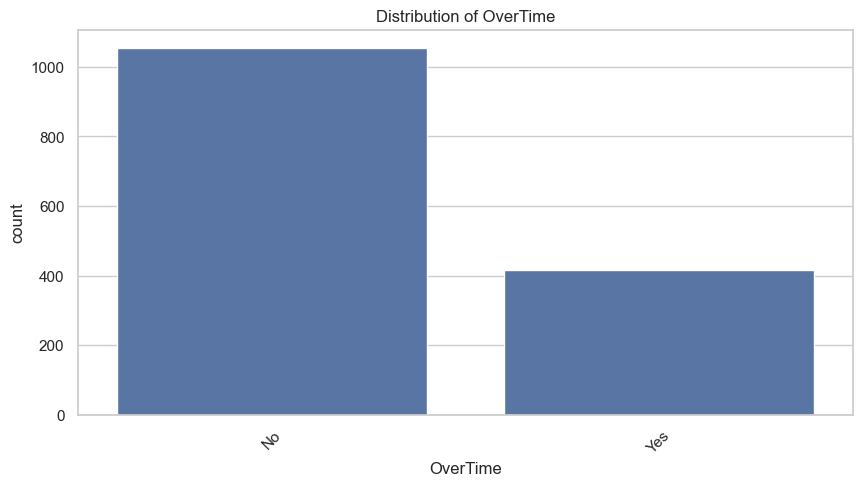

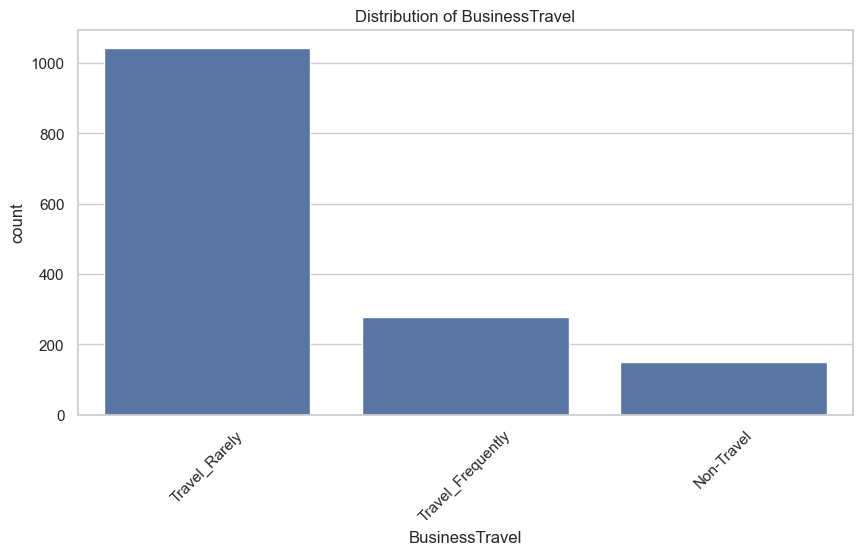

In [9]:
features = [
    'Department',
    'JobRole',
    'Gender',
    'MaritalStatus',
    'EducationField',
    'OverTime',
    'BusinessTravel'
]

for col in features:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index
    )

    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=45)
    plt.show()

# Attrition Rates analysis

In [10]:


department_attrition = pd.crosstab(
    df['Department'],
    df['Attrition'],
    normalize='index'
) * 100

department_attrition

Attrition,No,Yes
Department,,
Human Resources,80.952381,19.047619
Research & Development,86.160250,13.839750
Sales,79.372197,20.627803


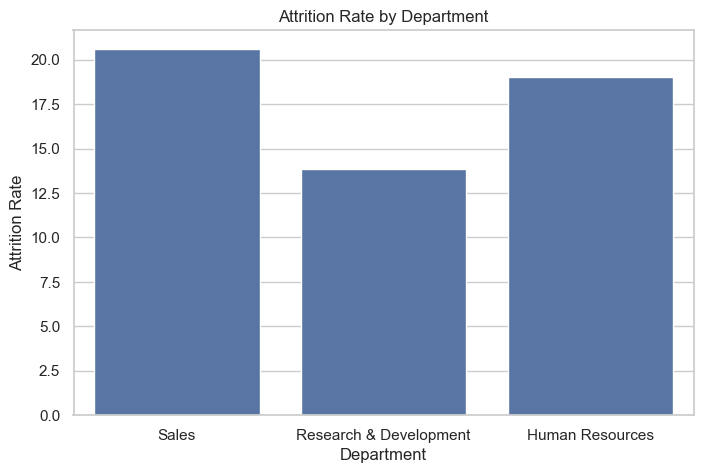

In [12]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Department',
    y=df['Attrition'].eq('Yes').astype(int)*100,
    errorbar=None
)

plt.title('Attrition Rate by Department')
plt.xlabel('Department')
plt.ylabel('Attrition Rate')

plt.show()

In [13]:
job_attrition = pd.crosstab(
    df['JobRole'],
    df['Attrition'],
    normalize='index'
) * 100

job_attrition.sort_values(
    by='Yes',
    ascending=False
)



Attrition,No,Yes
JobRole,,
Sales Representative,60.240964,39.759036
Laboratory Technician,76.061776,23.938224
Human Resources,76.923077,23.076923
Sales Executive,82.515337,17.484663
Research Scientist,83.904110,16.095890
Manufacturing Director,93.103448,6.896552
Healthcare Representative,93.129771,6.870229
Manager,95.098039,4.901961
Research Director,97.500000,2.500000


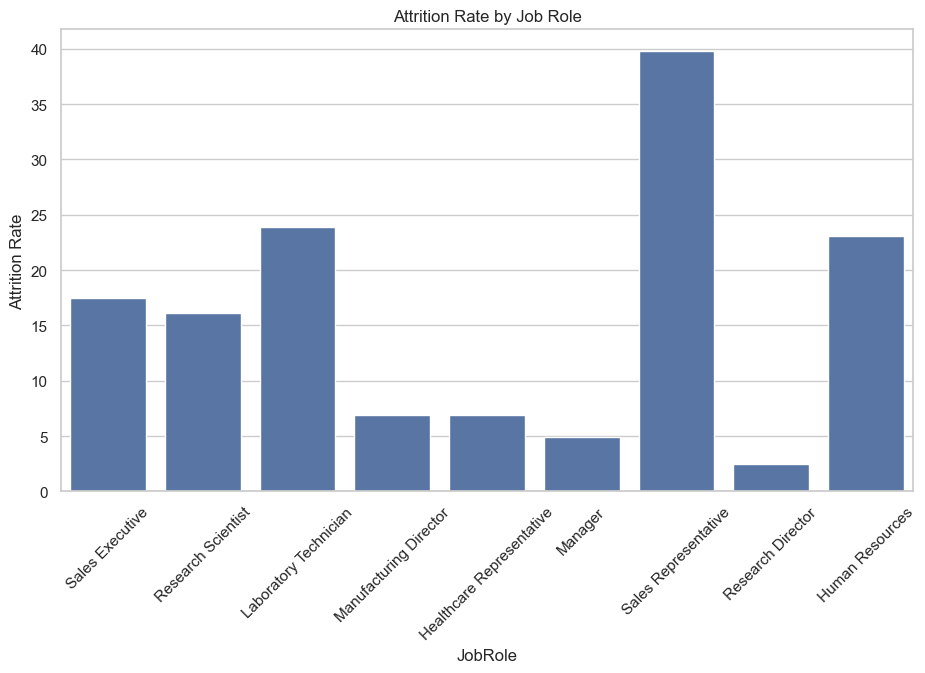

In [15]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=df,
    x='JobRole',
    y=df['Attrition'].eq('Yes').astype(int)*100,
    errorbar=None
)

plt.title('Attrition Rate by Job Role')
plt.xticks(rotation=45)
plt.ylabel('Attrition Rate')

plt.show()

In [16]:
overtime_attrition = pd.crosstab(
    df['OverTime'],
    df['Attrition'],
    normalize='index'
) * 100

overtime_attrition

Attrition,No,Yes
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


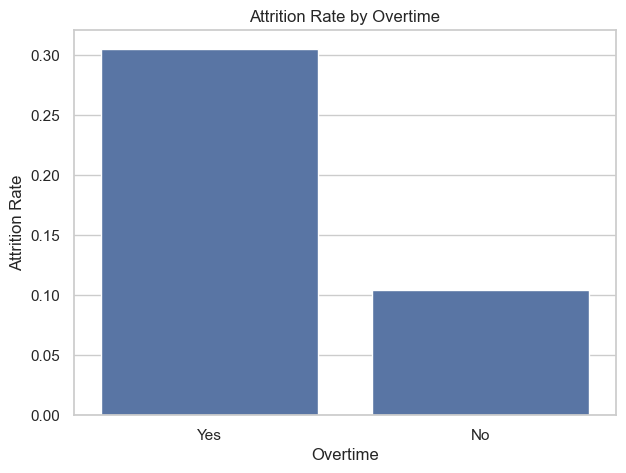

In [17]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x='OverTime',
    y=df['Attrition'].eq('Yes').astype(int),
    errorbar=None
)

plt.title('Attrition Rate by Overtime')
plt.xlabel('Overtime')
plt.ylabel('Attrition Rate')

plt.show()

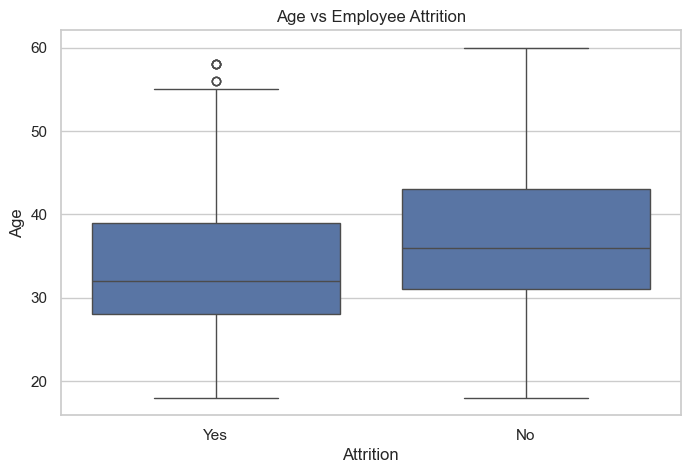

<Figure size 640x480 with 0 Axes>

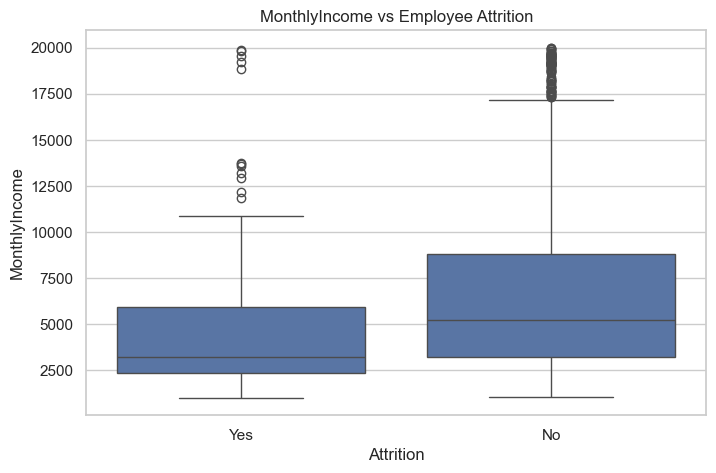

<Figure size 640x480 with 0 Axes>

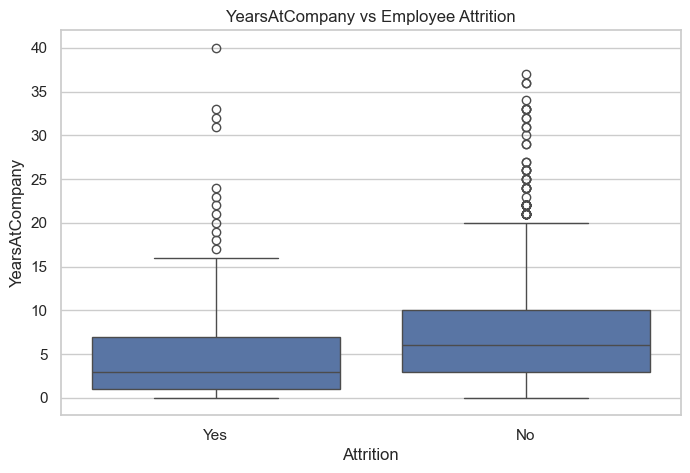

<Figure size 640x480 with 0 Axes>

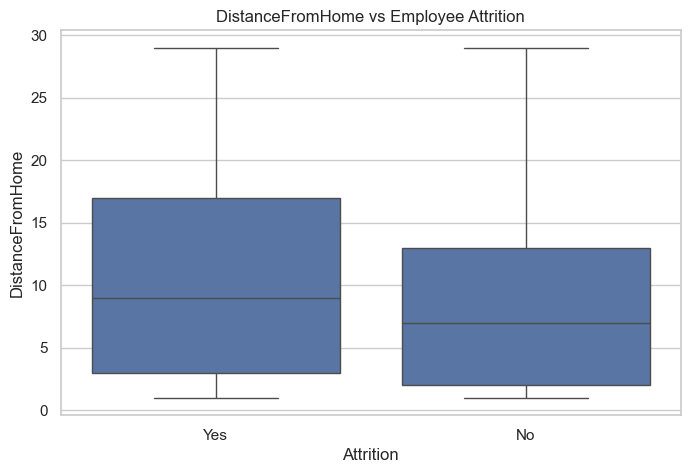

<Figure size 640x480 with 0 Axes>

In [21]:
features = [
    'Age',
    'MonthlyIncome',
    'YearsAtCompany',
    'DistanceFromHome'
]

for col in features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x='Attrition',
        y=col
    )

    plt.title(f'{col} vs Employee Attrition')
    plt.show()
    plt.savefig("boxplots")

In [22]:
numerical_comparison.T.round(2)

Attrition                            No      Yes
Age                     mean      37.56    33.61
                        median    36.00    32.00
MonthlyIncome           mean    6832.74  4787.09
                        median  5204.00  3202.00
TotalWorkingYears       mean      11.86     8.24
                        median    10.00     7.00
YearsAtCompany          mean       7.37     5.13
                        median     6.00     3.00
YearsInCurrentRole      mean       4.48     2.90
                        median     3.00     2.00
YearsSinceLastPromotion mean       2.23     1.95
                        median     1.00     1.00
YearsWithCurrManager    mean       4.37     2.85
                        median     3.00     2.00
DistanceFromHome        mean       8.92    10.63
                        median     7.00     9.00
JobSatisfaction         mean       2.78     2.47
                        median     3.00     3.00
EnvironmentSatisfaction mean       2.77     2.46
                        median     3.00     3.00
WorkLifeBalance         mean       2.78     2.66
                        median     3.00     3.00
JobInvolvement          mean       2.77     2.52
                        median     3.00     3.00

In [23]:
from scipy.stats import mannwhitneyu

In [24]:
stayed = df[df['Attrition'] == 'No']

left = df[df['Attrition'] == 'Yes']

In [25]:
statistic, p_value = mannwhitneyu(
    stayed['MonthlyIncome'],
    left['MonthlyIncome'],
    alternative='two-sided'
)

print("U Statistic:", statistic)
print("P-value:", p_value)

U Statistic: 191600.5
P-value: 2.950830917288873e-14


In [26]:
if p_value < 0.05:
    print("Statistically significant difference")
else:
    print("Insufficient evidence of a statistically significant difference")

Statistically significant difference


# corelation 

In [27]:
correlation = df.select_dtypes(
    include='number'
).corr(method='pearson')

correlation.round(2)

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
Age,1.00,0.01,-0.00,0.21,NaN,-0.01,0.01,0.02,0.03,0.51,...,0.05,NaN,0.04,0.68,-0.02,-0.02,0.31,0.21,0.22,0.20
DailyRate,0.01,1.00,-0.00,-0.02,NaN,-0.05,0.02,0.02,0.05,0.00,...,0.01,NaN,0.04,0.01,0.00,-0.04,-0.03,0.01,-0.03,-0.03
DistanceFromHome,-0.00,-0.00,1.00,0.02,NaN,0.03,-0.02,0.03,0.01,0.01,...,0.01,NaN,0.04,0.00,-0.04,-0.03,0.01,0.02,0.01,0.01
Education,0.21,-0.02,0.02,1.00,NaN,0.04,-0.03,0.02,0.04,0.10,...,-0.01,NaN,0.02,0.15,-0.03,0.01,0.07,0.06,0.05,0.07
EmployeeCount,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeNumber,-0.01,-0.05,0.03,0.04,NaN,1.00,0.02,0.04,-0.01,-0.02,...,-0.07,NaN,0.06,-0.01,0.02,0.01,-0.01,-0.01,-0.01,-0.01
EnvironmentSatisfaction,0.01,0.02,-0.02,-0.03,NaN,0.02,1.00,-0.05,-0.01,0.00,...,0.01,NaN,0.00,-0.00,-0.02,0.03,0.00,0.02,0.02,-0.00
HourlyRate,0.02,0.02,0.03,0.02,NaN,0.04,-0.05,1.00,0.04,-0.03,...,0.00,NaN,0.05,-0.00,-0.01,-0.00,-0.02,-0.02,-0.03,-0.02
JobInvolvement,0.03,0.05,0.01,0.04,NaN,-0.01,-0.01,0.04,1.00,-0.01,...,0.03,NaN,0.02,-0.01,-0.02,-0.01,-0.02,0.01,-0.02,0.03
JobLevel,0.51,0.00,0.01,0.10,NaN,-0.02,0.00,-0.03,-0.01,1.00,...,0.02,NaN,0.01,0.78,-0.02,0.04,0.53,0.39,0.35,0.38


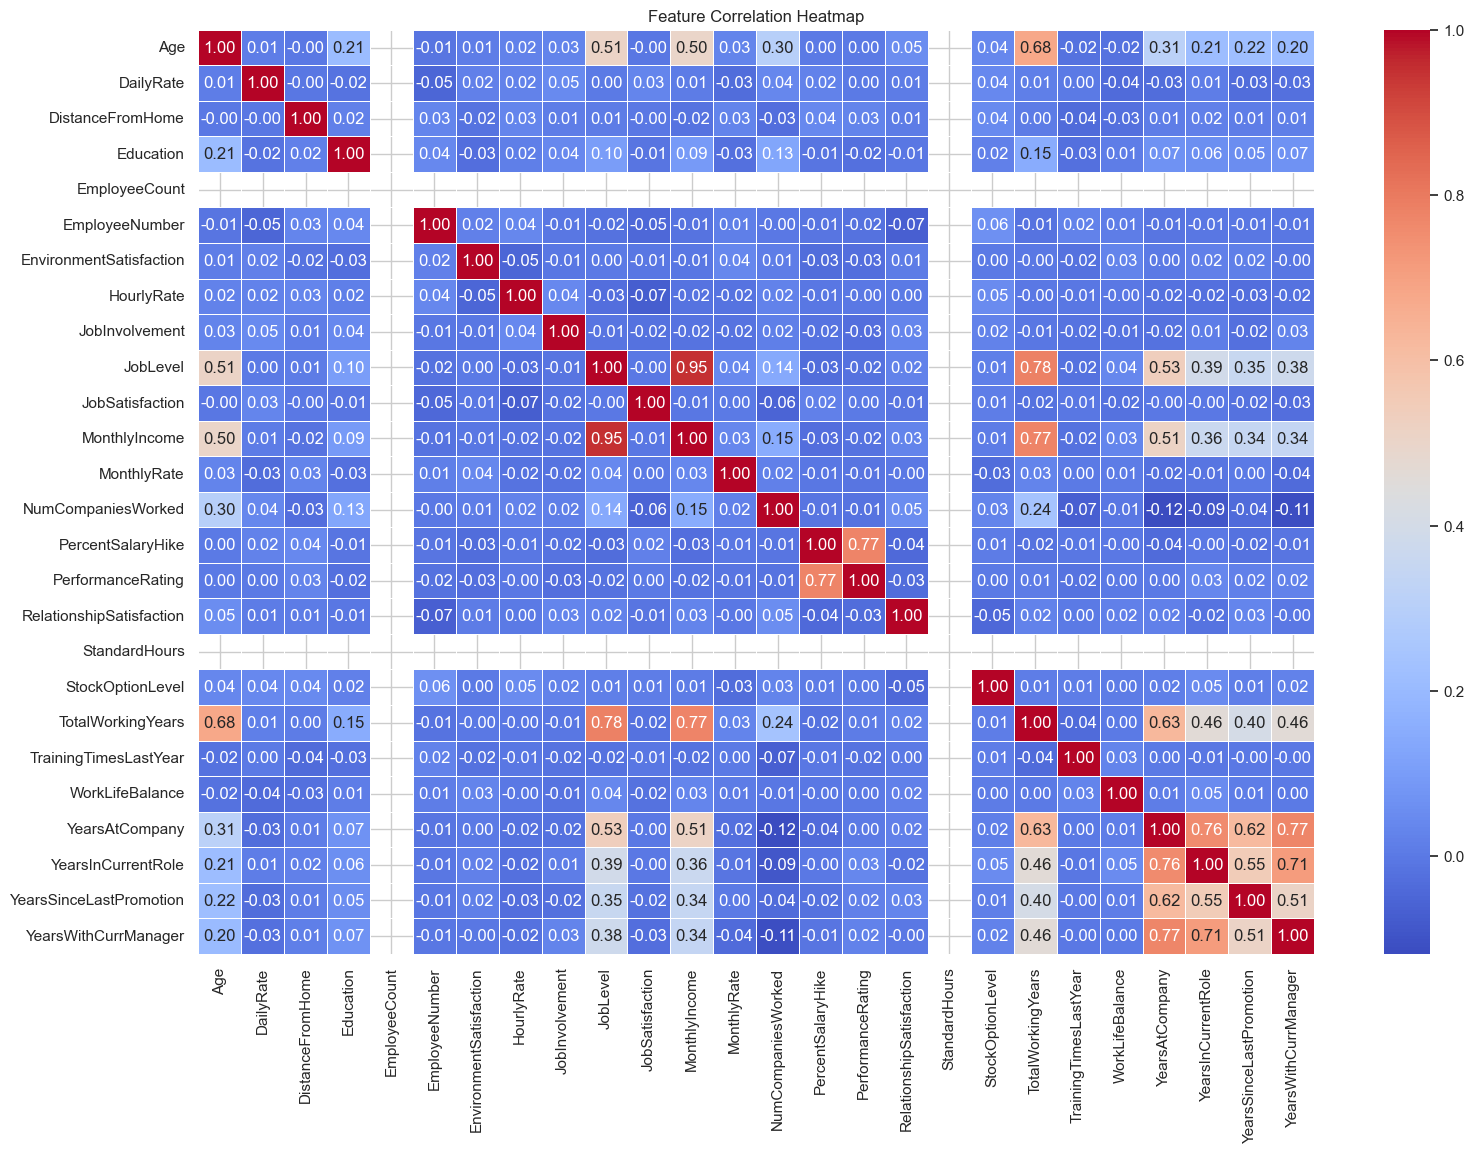

In [28]:
plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap')
plt.show()

In [29]:
# highly corelated cols

corr_pairs = correlation.unstack()

corr_pairs = corr_pairs[
    (corr_pairs != 1)
]

corr_pairs = corr_pairs.sort_values(
    ascending=False
)

corr_pairs.head(15)

JobLevel              MonthlyIncome           0.950300
MonthlyIncome         JobLevel                0.950300
TotalWorkingYears     JobLevel                0.782208
JobLevel              TotalWorkingYears       0.782208
PercentSalaryHike     PerformanceRating       0.773550
PerformanceRating     PercentSalaryHike       0.773550
MonthlyIncome         TotalWorkingYears       0.772893
TotalWorkingYears     MonthlyIncome           0.772893
YearsWithCurrManager  YearsAtCompany          0.769212
YearsAtCompany        YearsWithCurrManager    0.769212
YearsInCurrentRole    YearsAtCompany          0.758754
YearsAtCompany        YearsInCurrentRole      0.758754
YearsWithCurrManager  YearsInCurrentRole      0.714365
YearsInCurrentRole    YearsWithCurrManager    0.714365
TotalWorkingYears     Age                     0.680381
dtype: float64

In [32]:
#No corelation cols

corr_pairs.tail(25)

StandardHours            StandardHours             NaN
                         StockOptionLevel          NaN
                         TotalWorkingYears         NaN
                         TrainingTimesLastYear     NaN
                         WorkLifeBalance           NaN
                         YearsAtCompany            NaN
                         YearsInCurrentRole        NaN
                         YearsSinceLastPromotion   NaN
                         YearsWithCurrManager      NaN
StockOptionLevel         EmployeeCount             NaN
                         StandardHours             NaN
TotalWorkingYears        EmployeeCount             NaN
                         StandardHours             NaN
TrainingTimesLastYear    EmployeeCount             NaN
                         StandardHours             NaN
WorkLifeBalance          EmployeeCount             NaN
                         StandardHours             NaN
YearsAtCompany           EmployeeCount             NaN
          

In [33]:
df_corr = df.copy()

df_corr['Attrition_Encoded'] = (
    df_corr['Attrition'].map({'No': 0, 'Yes': 1})
)

attrition_corr = (
    df_corr.select_dtypes(include='number')
    .corr()['Attrition_Encoded']
    .drop('Attrition_Encoded')
    .sort_values()
)

attrition_corr

TotalWorkingYears          -0.171063
JobLevel                   -0.169105
YearsInCurrentRole         -0.160545
MonthlyIncome              -0.159840
Age                        -0.159205
YearsWithCurrManager       -0.156199
StockOptionLevel           -0.137145
YearsAtCompany             -0.134392
JobInvolvement             -0.130016
JobSatisfaction            -0.103481
EnvironmentSatisfaction    -0.103369
WorkLifeBalance            -0.063939
TrainingTimesLastYear      -0.059478
DailyRate                  -0.056652
RelationshipSatisfaction   -0.045872
YearsSinceLastPromotion    -0.033019
Education                  -0.031373
PercentSalaryHike          -0.013478
EmployeeNumber             -0.010577
HourlyRate                 -0.006846
PerformanceRating           0.002889
MonthlyRate                 0.015170
NumCompaniesWorked          0.043494
DistanceFromHome            0.077924
EmployeeCount                    NaN
StandardHours                    NaN
Name: Attrition_Encoded, dtype: float6